In [9]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from rdflib import Graph, RDF, RDFS, OWL

import matplotlib.pyplot as plt
import networkx as nx
from rdflib import Graph, RDF, RDFS, OWL

# 1. Xác định thư mục dự án
PROJECT_DIR = Path.cwd().resolve()

if PROJECT_DIR.name.lower() in ("notebook", "notebooks"):
    PROJECT_DIR = PROJECT_DIR.parent

# 2. Đường dẫn ontology gốc
OWL_FILE = (
    PROJECT_DIR
    / "data"
    / "ACME_Insurance"
    / "ontology"
    / "insurance.ttl"
)

# 3. Thư mục xuất các figure
FIGURE_DIR = (
    PROJECT_DIR
    / "results"
    / "figures"
    / "paper_reproduction"
)

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# 4. Kiểm tra
assert OWL_FILE.exists(), f"Missing ontology: {OWL_FILE}"

print("=== FIGURES ===")
print("Ontology:", OWL_FILE)
print("Output:", FIGURE_DIR)
print("Environment: OK")

=== FIGURES ===
Ontology: C:\Users\Win 11 New\Desktop\thuc-nghiem-co-so-httt\data\ACME_Insurance\ontology\insurance.ttl
Output: C:\Users\Win 11 New\Desktop\thuc-nghiem-co-so-httt\results\figures\paper_reproduction
Environment: OK


In [10]:
# 1. Đọc ontology
ontology = Graph()
ontology.parse(OWL_FILE, format="turtle")

# 2. Lấy danh sách các Class
classes = []

for cls in ontology.subjects(RDF.type, OWL.Class):
    classes.append(str(cls).split("/")[-1])

# 3. Lấy các quan hệ giữa Class
relations = []

for prop in ontology.subjects(RDF.type, OWL.ObjectProperty):
    domain = ontology.value(prop, RDFS.domain)
    range_ = ontology.value(prop, RDFS.range)

    if domain is not None and range_ is not None:
        relations.append((
            str(domain).split("/")[-1],
            str(range_).split("/")[-1],
            str(prop).split("/")[-1]
        ))

# 4. Kiểm tra
print("=== ONTOLOGY SUMMARY ===")
print("Classes:", len(classes))
print("Object Properties:", len(relations))

for source, target, relation in relations:
    print(f"{source} --{relation}--> {target}")

=== ONTOLOGY SUMMARY ===
Classes: 11
Object Properties: 10
Claim --against--> PolicyCoverageDetail
Claim --hasCatastrophe--> Catastrophe
Claim --hasExpensePayment--> ExpensePayment
Claim --hasExpenseReserve--> ExpenseReserve
Claim --hasLossPayment--> LossPayment
Claim --hasLossReserve--> LossReserve
PolicyCoverageDetail --hasPolicy--> Policy
Policy --hasPolicyHolder--> PolicyHolder
PolicyCoverageDetail --hasPremiumAmount--> Premium
Policy --soldByAgent--> Agent


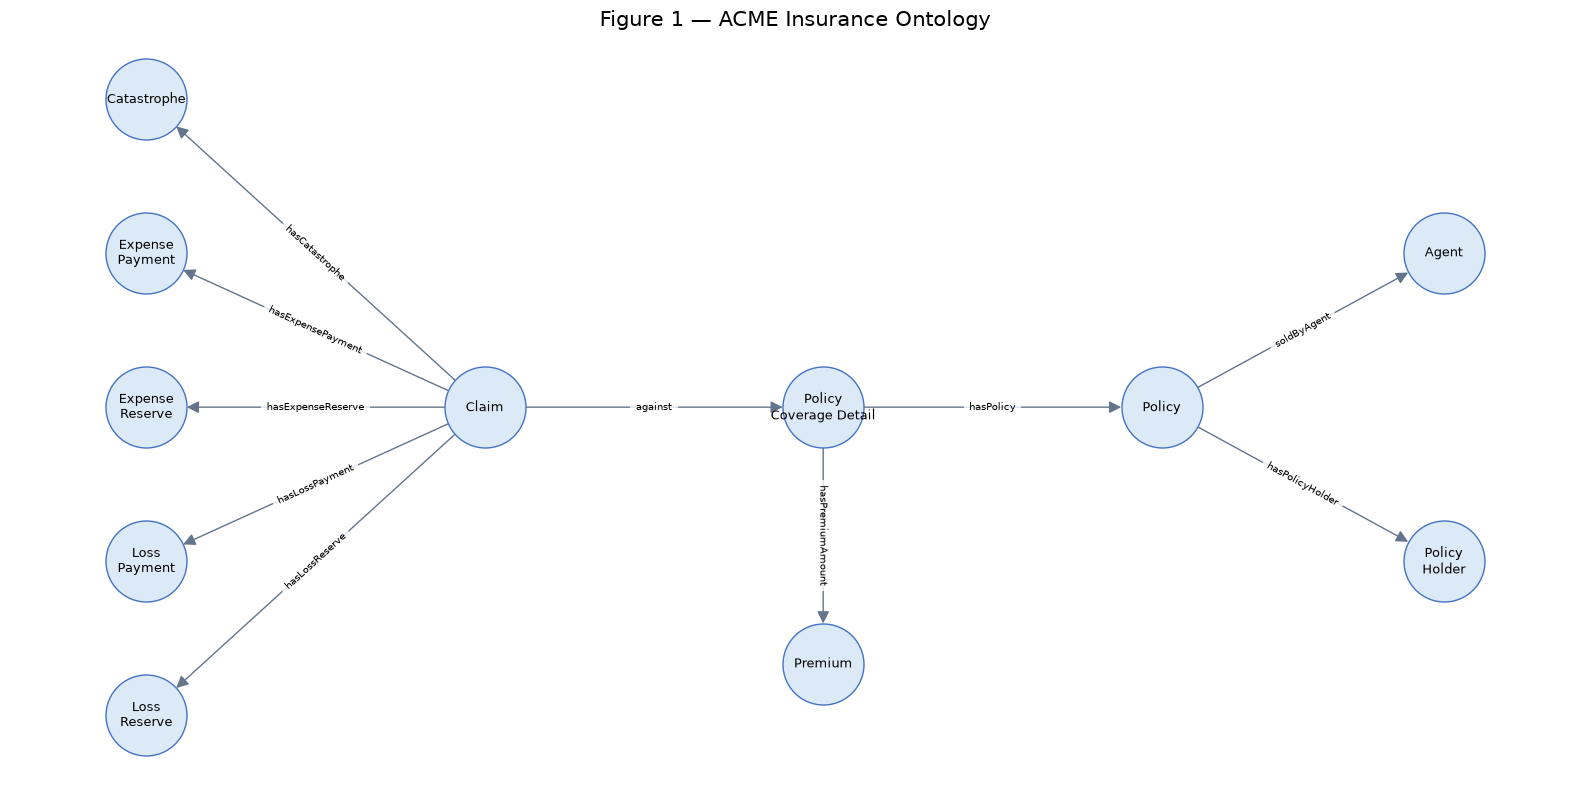

In [11]:
# 1. Tạo đồ thị
G = nx.DiGraph()
G.add_nodes_from(classes)

for source, target, relation in relations:
    G.add_edge(source, target, label=relation)

# 2. Bố cục cố định, dễ đọc hơn
pos = {
    "Claim": (-2, 0),
    "Catastrophe": (-5, 3),
    "ExpensePayment": (-5, 1.5),
    "ExpenseReserve": (-5, 0),
    "LossPayment": (-5, -1.5),
    "LossReserve": (-5, -3),

    "PolicyCoverageDetail": (1, 0),
    "Premium": (1, -2.5),

    "Policy": (4, 0),
    "Agent": (6.5, 1.5),
    "PolicyHolder": (6.5, -1.5)
}

# 3. Rút gọn nhãn dài
labels = {
    name: name.replace("CoverageDetail", "\nCoverage Detail")
              .replace("Payment", "\nPayment")
              .replace("Reserve", "\nReserve")
              .replace("Holder", "\nHolder")
    for name in classes
}

# 4. Vẽ
fig, ax = plt.subplots(figsize=(16, 8))

nx.draw_networkx_nodes(
    G, pos, ax=ax,
    node_size=3400,
    node_color="#DCEAF8",
    edgecolors="#4472C4"
)

nx.draw_networkx_labels(
    G, pos, labels=labels,
    font_size=9, ax=ax
)

nx.draw_networkx_edges(
    G, pos, ax=ax,
    node_size=3400,
    arrows=True,
    arrowsize=18,
    edge_color="#64748B"
)

nx.draw_networkx_edge_labels(
    G, pos, ax=ax,
    edge_labels=nx.get_edge_attributes(G, "label"),
    font_size=7,
    bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.8}
)

ax.set_title("Figure 1 — ACME Insurance Ontology", fontsize=15)
ax.axis("off")

plt.tight_layout()

# 5. Xuất hình
fig.savefig(FIGURE_DIR / "figure_01.png", dpi=300, bbox_inches="tight")
fig.savefig(FIGURE_DIR / "figure_01.svg", bbox_inches="tight")

plt.show()

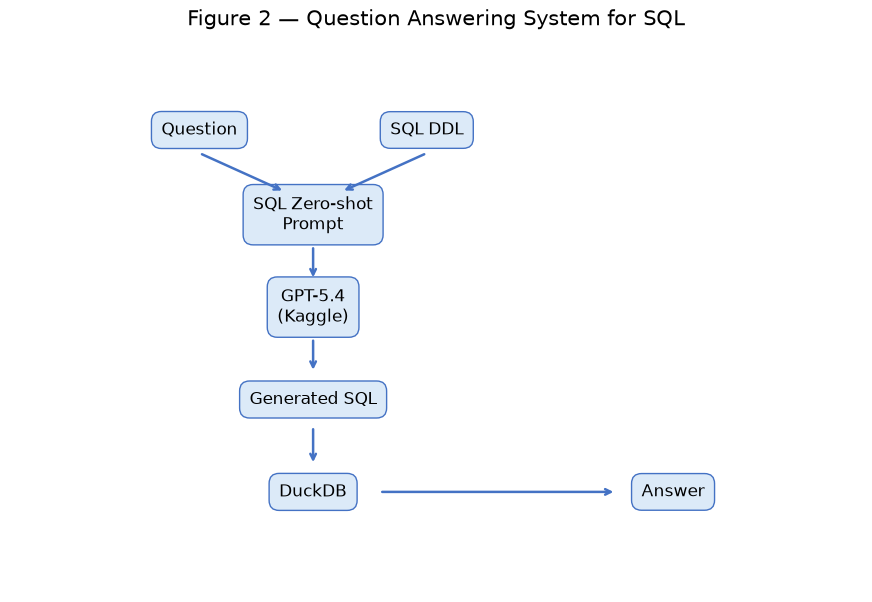

In [12]:
# 1. Tạo khung hình
fig, ax = plt.subplots(figsize=(11, 7))
ax.set_xlim(0, 9)
ax.set_ylim(0, 7)
ax.axis("off")

# 2. Các thành phần của hệ thống
boxes = [
    ("Question", 2, 6),
    ("SQL DDL", 4.4, 6),
    ("SQL Zero-shot\nPrompt", 3.2, 4.9),
    ("GPT-5.4\n(Kaggle)", 3.2, 3.7),
    ("Generated SQL", 3.2, 2.5),
    ("DuckDB", 3.2, 1.3),
    ("Answer", 7, 1.3)
]

for label, x, y in boxes:
    ax.text(
        x, y, label,
        ha="center", va="center",
        fontsize=12,
        bbox=dict(
            boxstyle="round,pad=0.6",
            facecolor="#DCEAF8",
            edgecolor="#4472C4"
        )
    )

# 3. Các mũi tên biểu diễn luồng xử lý
arrows = [
    ((2, 5.7), (2.9, 5.2)),
    ((4.4, 5.7), (3.5, 5.2)),
    ((3.2, 4.5), (3.2, 4.05)),
    ((3.2, 3.3), (3.2, 2.85)),
    ((3.2, 2.15), (3.2, 1.65)),
    ((3.9, 1.3), (6.4, 1.3))
]

for start, end in arrows:
    ax.annotate(
        "", xy=end, xytext=start,
        arrowprops=dict(
            arrowstyle="->",
            lw=1.8,
            color="#4472C4"
        )
    )

# 4. Tiêu đề
ax.set_title(
    "Figure 2 — Question Answering System for SQL",
    fontsize=15, pad=20
)

# 5. Xuất hình
fig.savefig(FIGURE_DIR / "figure_02.png", dpi=300, bbox_inches="tight")
fig.savefig(FIGURE_DIR / "figure_02.svg", bbox_inches="tight")

plt.show()


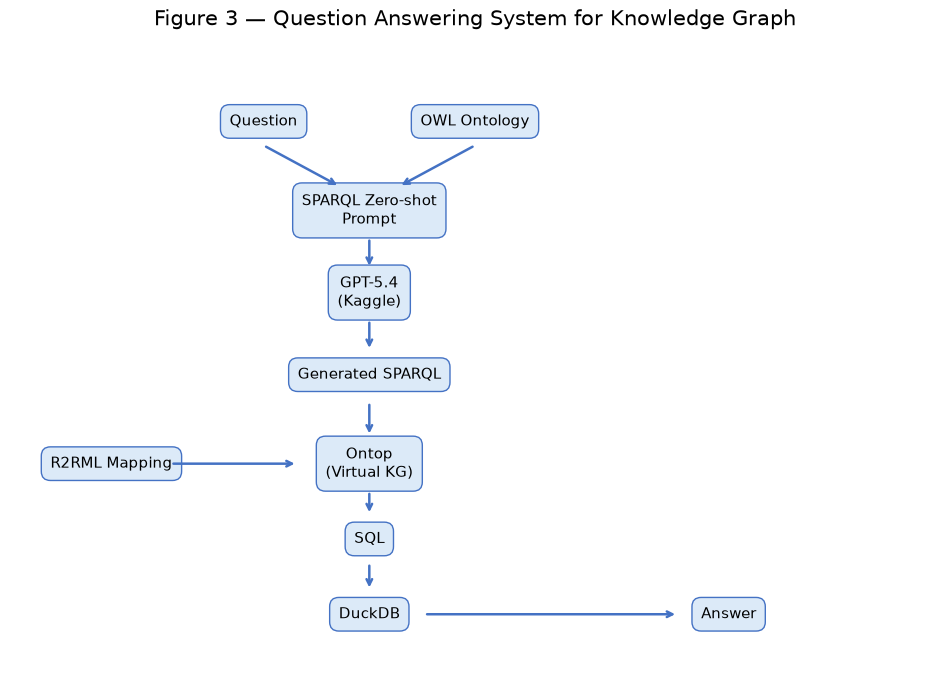

In [13]:
# 1. Tạo khung hình
fig, ax = plt.subplots(figsize=(12, 8))
ax.set_xlim(0, 11)
ax.set_ylim(0, 9)
ax.axis("off")

# 2. Các thành phần của hệ thống
boxes = [
    ("Question", 3, 8),
    ("OWL Ontology", 5.5, 8),
    ("SPARQL Zero-shot\nPrompt", 4.25, 6.7),
    ("GPT-5.4\n(Kaggle)", 4.25, 5.5),
    ("Generated SPARQL", 4.25, 4.3),
    ("Ontop\n(Virtual KG)", 4.25, 3),
    ("R2RML Mapping", 1.2, 3),
    ("SQL", 4.25, 1.9),
    ("DuckDB", 4.25, 0.8),
    ("Answer", 8.5, 0.8)
]

for label, x, y in boxes:
    ax.text(
        x, y, label,
        ha="center", va="center",
        fontsize=11,
        bbox=dict(
            boxstyle="round,pad=0.6",
            facecolor="#DCEAF8",
            edgecolor="#4472C4"
        )
    )

# 3. Các mũi tên
arrows = [
    ((3, 7.65), (3.9, 7.05)),
    ((5.5, 7.65), (4.6, 7.05)),
    ((4.25, 6.3), (4.25, 5.85)),
    ((4.25, 5.1), (4.25, 4.65)),
    ((4.25, 3.9), (4.25, 3.4)),
    ((1.9, 3), (3.4, 3)),
    ((4.25, 2.6), (4.25, 2.25)),
    ((4.25, 1.55), (4.25, 1.15)),
    ((4.9, 0.8), (7.9, 0.8))
]

for start, end in arrows:
    ax.annotate(
        "", xy=end, xytext=start,
        arrowprops=dict(
            arrowstyle="->",
            lw=1.8,
            color="#4472C4"
        )
    )

# 4. Tiêu đề
ax.set_title(
    "Figure 3 — Question Answering System for Knowledge Graph",
    fontsize=15,
    pad=20
)

# 5. Xuất hình
fig.savefig(
    FIGURE_DIR / "figure_03.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    FIGURE_DIR / "figure_03.svg",
    bbox_inches="tight"
)

plt.show()

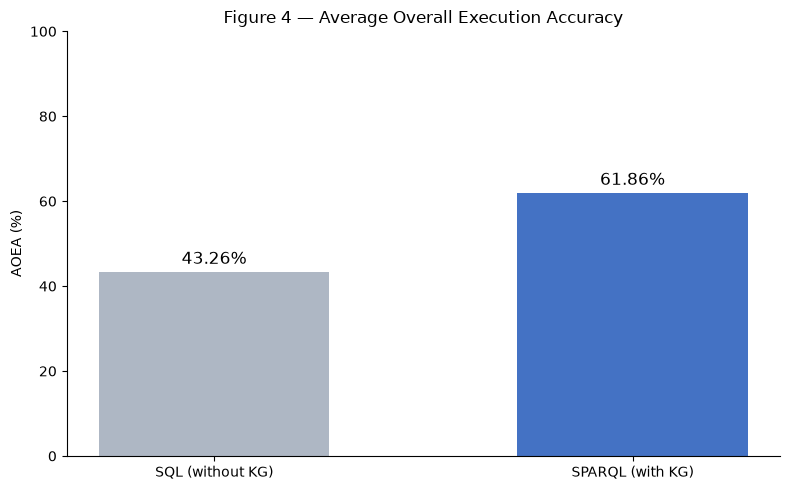

In [14]:
# 1. Đọc kết quả AOEA
aoea = pd.read_csv(
    PROJECT_DIR / "results/evaluation/aoea_summary.csv"
).set_index("Method")

methods = ["SQL", "SPARQL"]
scores = aoea.loc[methods, "AOEA"] * 100

# 2. Vẽ Figure 4
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    ["SQL (without KG)", "SPARQL (with KG)"],
    scores,
    color=["#AEB7C4", "#4472C4"],
    width=0.55
)

ax.set_ylim(0, 100)
ax.set_ylabel("AOEA (%)")
ax.set_title("Figure 4 — Average Overall Execution Accuracy")

# 3. Hiển thị giá trị
for bar, score in zip(bars, scores):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        score + 2,
        f"{score:.2f}%",
        ha="center",
        fontsize=12
    )

ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

# 4. Xuất hình
fig.savefig(FIGURE_DIR / "figure_04.png", dpi=300, bbox_inches="tight")
fig.savefig(FIGURE_DIR / "figure_04.svg", bbox_inches="tight")

plt.show()


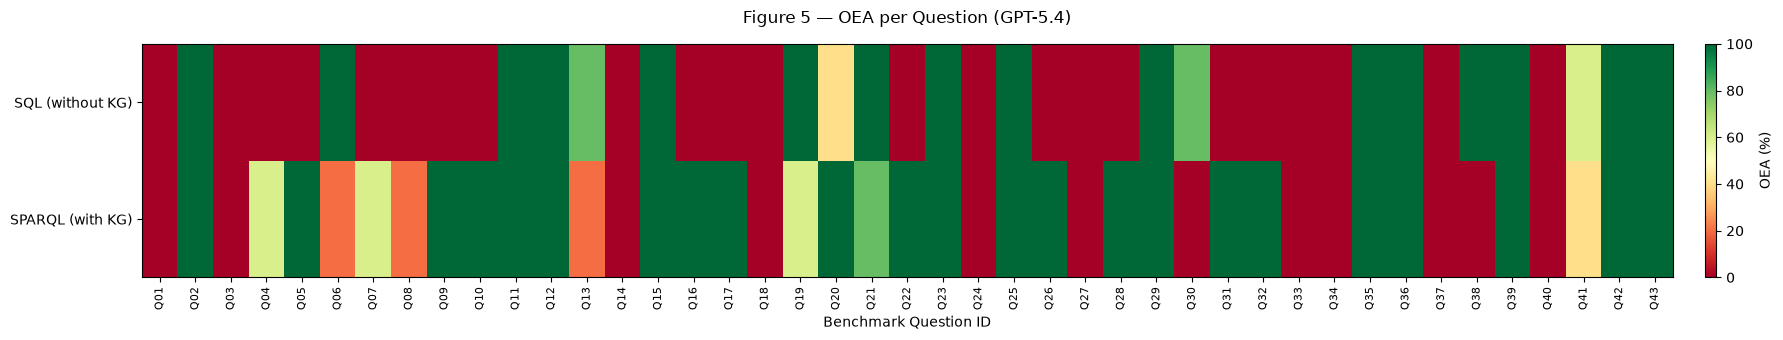

In [15]:
# 1. Đọc OEA của 43 câu hỏi
oea = pd.read_csv(
    PROJECT_DIR / "results/evaluation/oea_per_question.csv"
)

# 2. Chuyển thành bảng: 2 phương pháp × 43 câu hỏi
heatmap = oea.pivot(
    index="Method",
    columns="ID",
    values="OEA"
).loc[["SQL", "SPARQL"], range(1, 44)]

# 3. Vẽ heatmap
fig, ax = plt.subplots(figsize=(18, 3.5))

im = ax.imshow(
    heatmap.values,
    cmap="RdYlGn",
    vmin=0,
    vmax=1,
    aspect="auto"
)

ax.set_yticks([0, 1])
ax.set_yticklabels(["SQL (without KG)", "SPARQL (with KG)"])

ax.set_xticks(range(43))
ax.set_xticklabels(
    [f"Q{i:02d}" for i in range(1, 44)],
    rotation=90,
    fontsize=8
)

ax.set_xlabel("Benchmark Question ID")
ax.set_title("Figure 5 — OEA per Question (GPT-5.4)", pad=15)

# 4. Thanh màu
cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cbar.set_label("OEA (%)")
cbar.set_ticks([0, 0.2, 0.4, 0.6, 0.8, 1])
cbar.set_ticklabels(["0", "20", "40", "60", "80", "100"])

plt.tight_layout()

# 5. Xuất hình
fig.savefig(FIGURE_DIR / "figure_05.png", dpi=300, bbox_inches="tight")
fig.savefig(FIGURE_DIR / "figure_05.svg", bbox_inches="tight")

plt.show()


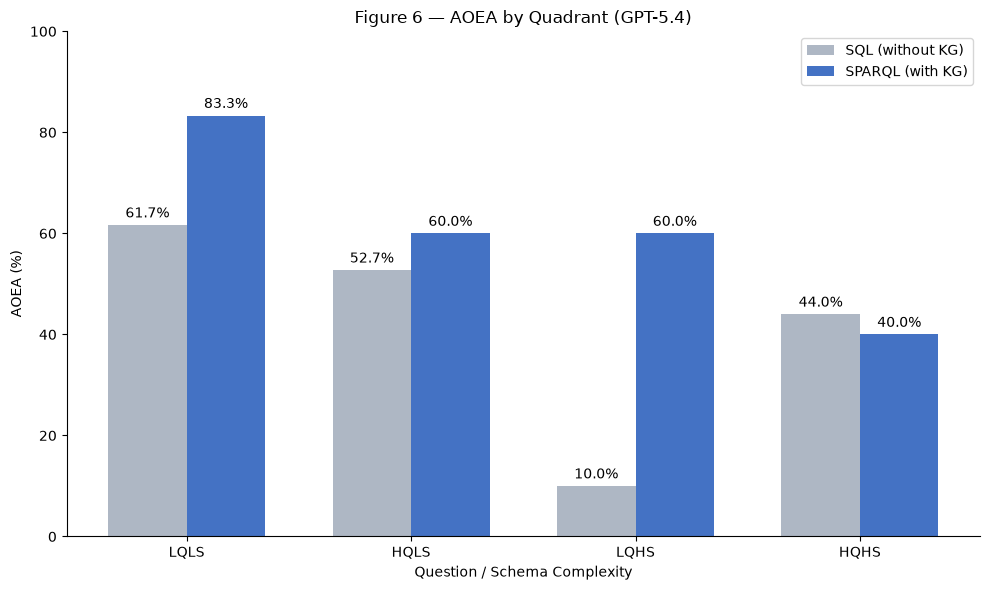

In [16]:
# 1. Đọc dữ liệu AOEA theo Quadrant
df = pd.read_csv(
    PROJECT_DIR / "results/evaluation/aoea_by_quadrant.csv"
)

quadrants = ["LQLS", "HQLS", "LQHS", "HQHS"]

table = df.pivot(
    index="Quadrant",
    columns="Method",
    values="AOEA"
).loc[quadrants] * 100

# 2. Vẽ biểu đồ
fig, ax = plt.subplots(figsize=(10, 6))

x = range(len(quadrants))
width = 0.35

sql_bars = ax.bar(
    [i - width / 2 for i in x],
    table["SQL"],
    width,
    label="SQL (without KG)",
    color="#AEB7C4"
)

sparql_bars = ax.bar(
    [i + width / 2 for i in x],
    table["SPARQL"],
    width,
    label="SPARQL (with KG)",
    color="#4472C4"
)

# 3. Nhãn và định dạng
ax.set_xticks(list(x))
ax.set_xticklabels(quadrants)
ax.set_ylim(0, 100)
ax.set_ylabel("AOEA (%)")
ax.set_xlabel("Question / Schema Complexity")
ax.set_title("Figure 6 — AOEA by Quadrant (GPT-5.4)")
ax.legend()

for bars in [sql_bars, sparql_bars]:
    for bar in bars:
        value = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 1.5,
            f"{value:.1f}%",
            ha="center",
            fontsize=10
        )

ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

# 4. Xuất hình
fig.savefig(FIGURE_DIR / "figure_06.png", dpi=300, bbox_inches="tight")
fig.savefig(FIGURE_DIR / "figure_06.svg", bbox_inches="tight")

plt.show()


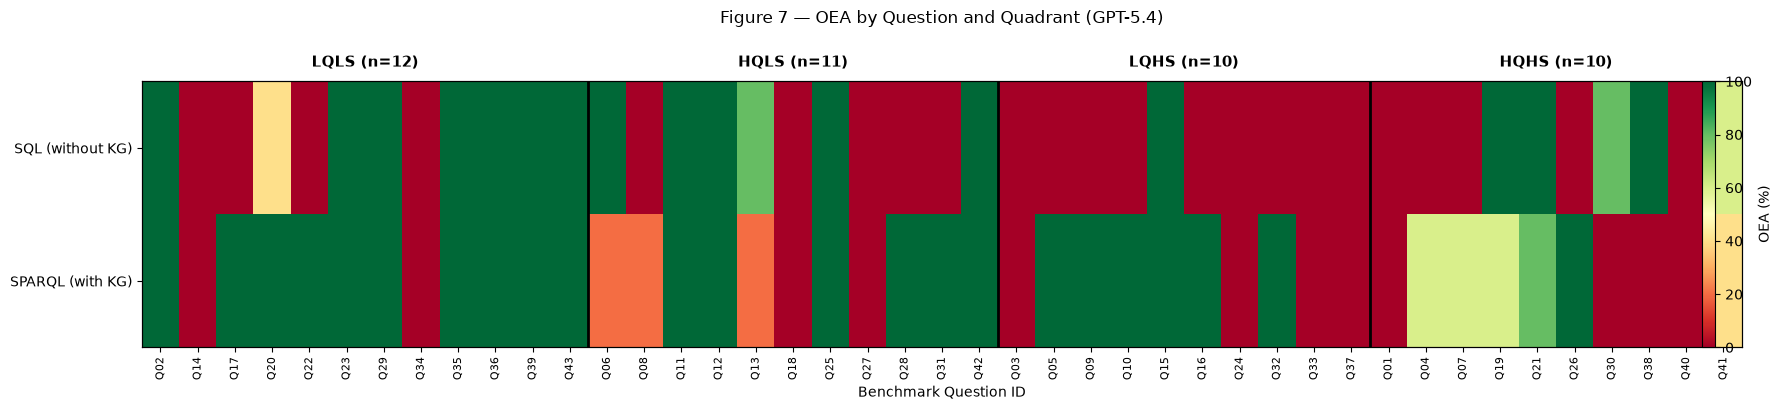

In [17]:
# 1. Đọc OEA và nhãn Quadrant
df = pd.read_csv(
    PROJECT_DIR / "results/evaluation/oea_by_quadrant.csv"
)

groups = ["LQLS", "HQLS", "LQHS", "HQHS"]

# 2. Sắp xếp câu hỏi theo Quadrant
questions = df[["ID", "Quadrant"]].drop_duplicates()

ordered_ids = []
centers = []
group_labels = []
boundaries = []

for group in groups:
    ids = sorted(
        questions.loc[questions["Quadrant"] == group, "ID"].tolist()
    )

    start = len(ordered_ids)
    ordered_ids.extend(ids)

    centers.append(start + (len(ids) - 1) / 2)
    group_labels.append(f"{group} (n={len(ids)})")
    boundaries.append(len(ordered_ids) - 0.5)

assert len(ordered_ids) == 43

# 3. Tạo ma trận OEA
heatmap = df.pivot(
    index="Method",
    columns="ID",
    values="OEA"
).loc[["SQL", "SPARQL"], ordered_ids]

# 4. Vẽ heatmap
fig, ax = plt.subplots(figsize=(18, 4.2))

im = ax.imshow(
    heatmap.values,
    cmap="RdYlGn",
    vmin=0,
    vmax=1,
    aspect="auto"
)

ax.set_yticks([0, 1])
ax.set_yticklabels(["SQL (without KG)", "SPARQL (with KG)"])

ax.set_xticks(range(43))
ax.set_xticklabels(
    [f"Q{i:02d}" for i in ordered_ids],
    rotation=90,
    fontsize=8
)

# 5. Đường phân cách Quadrant
for boundary in boundaries[:-1]:
    ax.axvline(boundary, color="black", linewidth=2)

# Tên Quadrant phía trên
top = ax.twiny()
top.set_xlim(ax.get_xlim())
top.set_xticks(centers)
top.set_xticklabels(group_labels, fontsize=11, fontweight="bold")
top.tick_params(axis="x", length=0, pad=8)

ax.set_xlabel("Benchmark Question ID")
ax.set_title(
    "Figure 7 — OEA by Question and Quadrant (GPT-5.4)",
    pad=42
)

# 6. Thanh màu
cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cbar.set_label("OEA (%)")
cbar.set_ticks([0, 0.2, 0.4, 0.6, 0.8, 1])
cbar.set_ticklabels(["0", "20", "40", "60", "80", "100"])

plt.tight_layout()

# 7. Xuất hình
fig.savefig(FIGURE_DIR / "figure_07.png", dpi=300, bbox_inches="tight")
fig.savefig(FIGURE_DIR / "figure_07.svg", bbox_inches="tight")

plt.show()
